# OP-FL v2 — 06c. Robustesse de la calibration de site sans label, comparateurs publiés et spécification gelée

**Point de départ (notebook 06b, verdict GO COMPLET).**
* Mortalité, `x_only` : les descripteurs sans label expliquent R²_τ = 0,60 [0,28 ; 0,93] de l'hétérogénéité des intercepts entre hôpitaux tenus à l'écart. C'est répliqué sur GRU-D (0,59) et sur `x_obs` (0,39).
* Avec k labels, l'a priori bayésien empirique domine à tous les k.
* Hyperlactatémie : γ = 0,93 [0,50 ; 1,37], alors que la théorie Y* = D × Y prédit 1.

**Ce que ce notebook vérifie avant d'ouvrir le test verrouillé** (hôpitaux de développement uniquement, aucun entraînement) :

1. **Comparateurs publiés sans label.** Trois méthodes corrigent déjà l'intercept d'un nouveau site à partir des seules prédictions sur ses patients :
   * l'ajustement de la prévalence sous décalage de labels par EM (Saerens, Latinne et Decaestecker 2002), après recalibration de l'intercept sur la source (Alexandari et al. 2020) ;
   * BBSE (Lipton et al. 2018, version à scores continus) ;
   * `E0` (aucune correction), qui correspond à un décalage de covariables pur avec un modèle bien spécifié.

   On teste aussi une variante combinée : l'estimation EM ajoutée comme descripteur (`S_all+EM`).
2. **Ce n'est pas du hasard.** Test par permutation : les vecteurs de descripteurs sont échangés entre hôpitaux, et toute la prédiction croisée est refaite.
3. **Ce n'est pas propre aux plis du protocole.** 50 partitions aléatoires des hôpitaux pour le méta-modèle, plus un leave-one-hospital-out.
4. **D'où vient le signal.** Ablation par groupe et par paire de groupes.
5. **Le méta-modèle se transporte d'un modèle à l'autre.** Il est appris sur les a_h de `x_only`, puis évalué sur ceux de GRU-D et de `x_obs`. C'est la situation du test verrouillé : le modèle final, entraîné sur les 60 hôpitaux, n'est pas celui des plis qui ont fourni les cibles.
6. **Spécification gelée.** Descripteurs, moteur, critères confirmatoires et règles, écrits **avant** toute lecture du test verrouillé.

La source d'un pli f est formée des patients `val` des hôpitaux d'entraînement de ce pli : leurs labels sont dans la fédération. Aucun label d'un hôpital tenu à l'écart n'est lu par EM, BBSE ou OP-Cal.

---

### Critères fixés avant les résultats (étape 8)

| Code | Question | Mesure (mortalité, `x_only`, `S_all`) | Rempli si |
|---|---|---|---|
| **R1** | Le R²_τ observé peut-il venir du hasard ? | p-valeur par permutation (500 permutations) | p < 0,05 |
| **R2** | Dépend-il des plis du protocole ? | médiane de R²_τ sur 50 partitions aléatoires | ≥ 0,25 |
| **R3** | OP-Cal bat-il le meilleur comparateur publié (E0, EM ou BBSE, celui qui a le plus petit \|CITL\| résiduel) ? | \|CITL\|(meilleur comparateur) − \|CITL\|(S_all) | borne basse de l'IC > 0 |
| **R3b** | Sinon, OP-Cal ajoute-t-il quelque chose à EM ? | \|CITL\|(EM) − \|CITL\|(S_all+EM) | borne basse de l'IC > 0 |

Descriptif : hyperlactatémie, `S_mech_fixe` (γ = 1, aucun coefficient ajusté) contre EM et BBSE ; ablation ; transfert entre modèles.

| Verdict | Condition | Spécification gelée |
|---|---|---|
| **GELÉE** | R1, R2 et R3 | `S_all` sans les descripteurs exclus par construction |
| **GELÉE AVEC EM** | R1, R2, non R3, R3b | idem + estimation EM comme descripteur |
| **À REVOIR** | sinon | écrite avec le statut « à revoir » : le notebook confirmatoire refusera de tourner |

**Exclusion par construction (fixée maintenant).** `log_size` est exclu : le test verrouillé ne contient que des hôpitaux de 100 à 499 séjours, et les hôpitaux de développement en ont au moins 500. Ce descripteur serait donc toujours hors du domaine appris. L'ablation de l'étape 6 indique ce que cette exclusion coûte sur les hôpitaux de développement.

**Garde-fous.** Du test verrouillé, seuls les effectifs `n_val` et `n_test` du manifest sont lus, pour fixer le k du critère confirmatoire. Aucun label, aucune prédiction et aucune colonne de mortalité ne sont lus. Seuls des agrégats sortent de ce notebook.

## Étape 0 — Configuration et critères

In [1]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION ET CRITÈRES (FIXÉS AVANT LES RÉSULTATS)
# ============================================================
import sys, json, importlib, warnings, time
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES02 = PROJECT_DIR / "results" / "02_baselines"
RES04 = PROJECT_DIR / "results" / "04_observation_label"
RES05 = PROJECT_DIR / "results" / "05_raccourci_masquage"
RES06B = PROJECT_DIR / "results" / "06b_faisabilite_opcal"
RES_DIR = PROJECT_DIR / "results" / "06c_robustesse_opcal"
FIG_DIR = RES_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
FOLDS = sorted(int(k) for k in protocol["folds"])
FOLD_OF = {int(h): int(k) for k in protocol["folds"] for h in protocol["folds"][k]}
DEV = sorted(FOLD_OF)
LOCKED = set(int(h) for h in protocol["locked_test_hospitals"])
STAY_LABELS = RES04 / "stay_labels.parquet"
assert (SRC_DIR / "opcal_feas.py").exists() and (RES06B / "regime0.csv").exists(), "Exécuter d'abord le notebook 06b."
VERDICT_06B = pd.read_csv(RES06B / "criteres_06b.csv")

TASKS = {
    "mortalite_x_only": {"pred_dir": RES02 / "preds", "name": "x_only", "label": "y_mortality", "pop": "tous", "role": "principal"},
    "mortalite_x_obs":  {"pred_dir": RES02 / "preds", "name": "x_obs", "label": "y_mortality", "pop": "tous", "role": "secondaire"},
    "mortalite_grud":   {"pred_dir": RES02 / "preds", "name": "grud", "label": "y_mortality", "pop": "tous", "role": "secondaire"},
    "lactate_x_only":   {"pred_dir": RES05 / "preds", "name": "A_lac_neg_x_only", "label": "hyper_neg", "pop": "present48",
                         "role": "mécanisme", "mech": "test_rate_lactate"},
    "lactate_x_obs":    {"pred_dir": RES05 / "preds", "name": "A_lac_neg_x_obs", "label": "hyper_neg", "pop": "present48",
                         "role": "secondaire", "mech": "test_rate_lactate"},
    "aki_x_only":       {"pred_dir": RES05 / "preds", "name": "A_aki_neg_x_only", "label": "aki_neg", "pop": "present48_crbase",
                         "role": "contraste", "mech": "test_rate_creatinine"},
}
PRIMARY, MECH_TASK = "mortalite_x_only", "lactate_x_only"
GROUPS_ALL = ["obs", "case", "struct", "model"]
EXCLUDED_BY_CONSTRUCTION = {"log_size": "test verrouillé = hôpitaux de 100 à 499 séjours ; développement ≥ 500 : toujours hors domaine"}

CRIT = {"R1_p": 0.05, "R2_R2tau": 0.25}
N_PERM, N_PERM_SEC, N_PART = 500, 200, 50
N_BOOT, SEED = 2000, 2026
(RES_DIR / "config.json").write_text(json.dumps(
    {"protocol_hash": protocol["hash"], "criteria": CRIT, "n_perm": N_PERM, "n_perm_secondary": N_PERM_SEC, "n_partitions": N_PART,
     "n_boot": N_BOOT, "seed": SEED, "excluded_by_construction": EXCLUDED_BY_CONSTRUCTION,
     "created_at": datetime.now().isoformat(timespec="seconds")}, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Protocole {protocol['hash']} | {len(DEV)} hôpitaux de développement | test verrouillé : {len(LOCKED)} hôpitaux (non chargés)")
print("Verdict 06b :", "rempli : " + ", ".join(VERDICT_06B.loc[VERDICT_06B["rempli"], "code"]))

Protocole d92099ea7c11d517 | 60 hôpitaux de développement | test verrouillé : 96 hôpitaux (non chargés)
Verdict 06b : rempli : F1, F2, F3


## Étape 1 — Module `src/opcal_robust.py`

Comparateurs publiés (EM, BBSE), tests de robustesse, transfert entre modèles. `src/opcal_feas.py` (notebook 06b) est réutilisé sans modification ; son empreinte est enregistrée dans la spécification gelée.

In [2]:
# %%writefile ../src/opcal_robust.py
# """
# opcal_robust — robustesse de la calibration de site sans label (OP-Cal) et comparateurs publiés.

# Généré par notebooks/06c_robustesse_opcal.ipynb (étape 1) : modifier le notebook, pas ce fichier.
# S'appuie sur src/opcal_feas.py (notebook 06b), qui n'est pas modifié.

# Comparateurs sans label publiés, qui corrigent eux aussi l'intercept d'un site à partir des seules
# prédictions sur ses patients (sans label) :
#   - E0 : aucune correction = hypothèse d'un décalage de covariables pur avec un modèle bien spécifié ;
#   - EM : ajustement de la prévalence sous décalage de labels (Saerens, Latinne et Decaestecker 2002),
#          après recalibration de l'intercept sur la source (variante « bias-corrected », Alexandari et al. 2020) ;
#   - BBSE : estimation de la prévalence par le moment E_t[q] = pi_t m1 + (1 - pi_t) m0 (Lipton et al. 2018,
#            version à scores continus).
# La source d'un pli f = les patients `val` des hôpitaux d'entraînement de ce pli (labels autorisés : ils sont
# dans la fédération). Aucune de ces méthodes ne lit un label de l'hôpital tenu à l'écart.
# """
# import hashlib
# from pathlib import Path

# import numpy as np
# import pandas as pd

# import opcal_feas as oc


# # ----------------------------------------------------------------------------------------------
# # Prédictions d'un rôle donné (val = source du pli ; transfer = hôpitaux tenus à l'écart)
# # ----------------------------------------------------------------------------------------------

# def load_role(pred_dir, name, folds, role, seeds=None):
#     """Prédictions d'un rôle, moyennées sur les seeds, une ligne par (pli, séjour)."""
#     runs = oc.list_runs(pred_dir)
#     r = runs[runs["name"] == name]
#     if r.empty:
#         raise FileNotFoundError(f"Aucune prédiction pour '{name}' dans {pred_dir}")
#     if seeds is None:
#         seeds = [s for s in sorted(r["seed"].unique()) if set(r.loc[r["seed"] == s, "fold"]) >= set(folds)]
#     parts = []
#     for _, row in r[r["seed"].isin(seeds) & r["fold"].isin(folds)].iterrows():
#         d = pd.read_parquet(row["path"])
#         d = d[d["role"] == role]
#         cols = ["stay_id", "hospitalid", "p"] + (["y"] if "y" in d.columns else [])
#         parts.append(d[cols].assign(fold=row["fold"], seed=row["seed"]))
#     if not parts:
#         raise RuntimeError(f"'{name}' : aucune ligne de rôle '{role}'")
#     d = pd.concat(parts, ignore_index=True)
#     agg = {"hospitalid": ("hospitalid", "first"), "p": ("p", "mean"), "n_seeds": ("seed", "nunique")}
#     if "y" in d.columns:
#         agg["y"] = ("y", "first")
#     out = d.groupby(["fold", "stay_id"]).agg(**agg).reset_index()
#     out["lp"] = oc.logit(out["p"].to_numpy())
#     return out, seeds


# def source_reference(val):
#     """Par pli : décalage a_s qui calibre le score sur la source, prévalence pi_s,
#     moyennes m1 = E_s[q | y = 1] et m0 = E_s[q | y = 0] du score recalibré q."""
#     rows = {}
#     for f, g in val.groupby("fold"):
#         lp, y = g["lp"].to_numpy(), g["y"].to_numpy(float)
#         a_s, _ = oc.offset_fit(lp, y)
#         q = oc.sigmoid(lp + a_s)
#         rows[int(f)] = {"a_s": a_s, "pi_s": float(y.mean()), "m1": float(q[y == 1].mean()),
#                         "m0": float(q[y == 0].mean()), "n_source": len(g), "hopitaux_source": g["hospitalid"].nunique()}
#     return pd.DataFrame(rows).T


# def em_prior(q, pi_s, max_iter=1000, tol=1e-10):
#     """EM de Saerens et al. (2002) pour un label binaire : prévalence cible pi_t à partir des
#     probabilités a posteriori q (calibrées pour la prévalence source pi_s)."""
#     q = np.clip(np.asarray(q, float), 1e-9, 1 - 1e-9)
#     pi = float(pi_s)
#     for _ in range(max_iter):
#         r1, r0 = pi / pi_s, (1 - pi) / (1 - pi_s)
#         new = float(np.mean(r1 * q / (r1 * q + r0 * (1 - q))))
#         if abs(new - pi) < tol:
#             pi = new
#             break
#         pi = new
#     return float(np.clip(pi, 1e-5, 1 - 1e-5))


# def label_shift_predictions(stays, ref):
#     """Décalage d'intercept prédit sans label pour chaque hôpital tenu à l'écart :
#     a = a_s + logit(pi_t) - logit(pi_s), avec pi_t estimé par EM ou par BBSE."""
#     rows = []
#     for h, g in stays.groupby("hospitalid"):
#         f = int(g["fold"].iloc[0])
#         s = ref.loc[f]
#         q = oc.sigmoid(g["lp"].to_numpy() + s["a_s"])
#         pi_em = em_prior(q, s["pi_s"])
#         pi_bb = float(np.clip((q.mean() - s["m0"]) / max(s["m1"] - s["m0"], 1e-6), 1e-5, 1 - 1e-5))
#         base = s["a_s"] - oc.logit(s["pi_s"])
#         rows.append({"hospitalid": int(h), "fold": f, "a_EM": float(base + oc.logit(pi_em)),
#                      "a_BBSE": float(base + oc.logit(pi_bb)), "a_source": float(s["a_s"]),
#                      "pi_em": pi_em, "pi_bbse": pi_bb})
#     return pd.DataFrame(rows).set_index("hospitalid").sort_index()


# def as_prior(a_hat, index):
#     return pd.DataFrame({"a_hat": pd.Series(a_hat, index=index).reindex(index).to_numpy(float),
#                          "pred_var": np.nan, "tau2_raw": np.nan, "tau2_resid": np.nan, "hyper": np.nan, "mu": np.nan},
#                         index=index)


# def paired_abs(cal, prior_a, prior_b, n_boot=2000, seed=0):
#     """Moyenne sur les hôpitaux de |résidu|(a) − |résidu|(b) (> 0 : b meilleur), IC bootstrap des hôpitaux."""
#     ra = (cal["citl"] - prior_a["a_hat"].reindex(cal.index)).abs().to_numpy()
#     rb = (cal["citl"] - prior_b["a_hat"].reindex(cal.index)).abs().to_numpy()
#     return oc.boot_mean_diff(ra, rb, n_boot, seed)


# # ----------------------------------------------------------------------------------------------
# # Robustesse du régime 0
# # ----------------------------------------------------------------------------------------------

# def permutation_test(cal, D, cols, n_perm=500, seed=0, fixed_beta=None):
#     """Permute les vecteurs de descripteurs entre hôpitaux (la structure entre descripteurs est gardée),
#     refait toute la prédiction croisée, et compare R2_tau observé à sa distribution sous H0."""
#     D = D.loc[cal.index]
#     obs = oc.evaluate_prior(cal, oc.crossfit_prior(cal, D, cols, fixed_beta=fixed_beta))["R2_tau"]
#     if not np.isfinite(obs):          # tau2 brut nul : aucune hétérogénéité à expliquer
#         return float("nan"), np.full(n_perm, np.nan), float("nan")
#     rng = np.random.default_rng(seed)
#     null = np.empty(n_perm)
#     vals = D.to_numpy()
#     for b in range(n_perm):
#         Dp = pd.DataFrame(vals[rng.permutation(len(D))], index=D.index, columns=D.columns)
#         null[b] = oc.evaluate_prior(cal, oc.crossfit_prior(cal, Dp, cols, fixed_beta=fixed_beta))["R2_tau"]
#     p = float((1 + np.sum(np.nan_to_num(null, nan=-np.inf) >= obs)) / (n_perm + 1))
#     return float(obs), null, p


# def repeated_partitions(cal, D, cols, n_rep=50, n_folds=5, seed=0, fixed_beta=None):
#     """R2_tau quand le méta-modèle est croisé sur des partitions aléatoires des hôpitaux (les cibles a_h,
#     elles, restent celles des plis du protocole)."""
#     rng = np.random.default_rng(seed)
#     out = []
#     for r in range(n_rep):
#         f = np.empty(len(cal), int)
#         f[rng.permutation(len(cal))] = np.arange(len(cal)) % n_folds
#         c2 = cal.copy()
#         c2["fold"] = f
#         out.append({"rep": r, **oc.evaluate_prior(cal, oc.crossfit_prior(c2, D, cols, fixed_beta=fixed_beta))})
#     return pd.DataFrame(out)


# def leave_one_hospital_out(cal, D, cols, fixed_beta=None):
#     c2 = cal.copy()
#     c2["fold"] = np.arange(len(cal))
#     pr = oc.crossfit_prior(c2, D, cols, fixed_beta=fixed_beta)
#     return oc.evaluate_prior(cal, pr), pr


# def crossfit_transfer(cal_src, D_src, cal_tgt, D_tgt, cols):
#     """Méta-modèle appris sur les a_h d'un modèle (source), appliqué aux descripteurs et évalué sur les a_h
#     d'un autre modèle (cible), croisé par pli : la situation du test verrouillé, où le modèle final n'est pas
#     celui des plis qui ont fourni les cibles d'apprentissage."""
#     out = []
#     for f in sorted(cal_tgt["fold"].unique()):
#         tr = cal_src[cal_src["fold"] != f]
#         te = cal_tgt.index[cal_tgt["fold"] == f]
#         m = oc.SiteEB().fit(D_src.loc[tr.index, cols].to_numpy(float), tr["citl"].to_numpy(), tr["var_citl"].to_numpy())
#         mean, var = m.predict(D_tgt.loc[te, cols].to_numpy(float))
#         out.append(pd.DataFrame({"a_hat": mean, "pred_var": var, "tau2_raw": np.nan, "tau2_resid": m.tau2,
#                                  "hyper": m.s2b, "mu": m.mu}, index=te))
#     return pd.concat(out).sort_index()


# def sha256(path):
#     return hashlib.sha256(Path(path).read_bytes()).hexdigest()

## Étape 2 — Cibles et descripteurs (identiques au notebook 06b)

Même code que les étapes 2 à 4 du 06b. Le contrôle de l'étape 10 vérifie que le R²_τ principal est reproduit exactement.

In [3]:
# ============================================================
# ÉTAPE 2 — CIBLES a_h ET DESCRIPTEURS (REPRISE DU 06b)
# ============================================================
import opcal_feas as oc, opcal_robust as orb
for m in (oc, orb):
    importlib.reload(m)

st = pd.read_parquet(STAY_LABELS).set_index("stay_id")
POP = {"tous": st.index, "present48": st.index[st["present48"].astype(bool)],
       "present48_crbase": st.index[st["present48"].astype(bool) & st["cr_base"].notna()]}

def attach_labels(d, c_):
    if c_["label"] != "y_mortality" or "y" not in d.columns:
        d = d.drop(columns="y", errors="ignore")
        d = d[d["stay_id"].isin(POP[c_["pop"]])].copy()
        d["y"] = d["stay_id"].map(st[c_["label"]]).astype(float)
    return d[d["y"].notna()].reset_index(drop=True)

CAL, STAYS, SEEDS_USED = {}, {}, {}
for t, c_ in TASKS.items():
    try:
        d, seeds = oc.load_transfer(c_["pred_dir"], c_["name"], FOLDS)
    except (FileNotFoundError, RuntimeError) as e:
        if c_["role"] == "principal":
            raise
        print(f"{t} : ignorée ({e})")
        continue
    d = attach_labels(d, c_)
    CAL[t], STAYS[t], SEEDS_USED[t] = oc.hospital_calibration(d), d, seeds

D_SITE, GROUPS = oc.site_descriptors(DATA_DIR, STAY_LABELS, DEV)
for v in ("lactate", "creatinine"):
    D_SITE[f"log_test_rate_{v}"] = np.log(D_SITE[f"test_rate_{v}"].clip(lower=1e-3))

def desc_for(t):
    D = D_SITE.join(CAL[t][["mean_lp", "sd_lp"]])
    G = {**GROUPS, "model": ["mean_lp", "sd_lp"]}
    if "mech" in TASKS[t]:
        G["mech"] = ["log_" + TASKS[t]["mech"]]
    return D, G

def cols_of(t, groups, drop=()):
    G = desc_for(t)[1]
    return [c for g in groups for c in G[g] if c not in drop]

def prior(t, spec, D=None, extra=()):
    """spec : 'E0', 'E1', 'fixe' (mécanisme, γ = 1) ou une liste de groupes."""
    cal = CAL[t]
    D_, G = desc_for(t)
    D = D_ if D is None else D
    if spec == "E0":
        return orb.as_prior(0.0, cal.index)
    if spec == "E1":
        return oc.crossfit_prior(cal, D, [])
    if spec == "fixe":
        return oc.crossfit_prior(cal, D, [], fixed_beta=(G["mech"][0], 1.0))
    return oc.crossfit_prior(cal, D, cols_of(t, spec) + list(extra))

ref06b = pd.read_csv(RES06B / "regime0.csv").set_index(["tâche", "ensemble"])
r2_now = oc.evaluate_prior(CAL[PRIMARY], prior(PRIMARY, GROUPS_ALL))["R2_tau"]
print(f"R²_τ {PRIMARY} / S_all : {r2_now:.4f} (06b : {ref06b.loc[(PRIMARY, 'S_all'), 'R2_tau']:.4f})")

R²_τ mortalite_x_only / S_all : 0.5946 (06b : 0.5946)


## Étape 3 — Comparateurs publiés sans label : EM et BBSE

Pour le pli f, la source est formée des patients `val` des 48 hôpitaux d'entraînement. On y calcule le décalage a_s qui calibre le score, la prévalence π_s, et E[q | y].
Pour chaque hôpital tenu à l'écart, la prévalence π_t est estimée à partir des seules prédictions q sur ses patients. Le décalage prédit est a = a_s + logit(π_t) − logit(π_s).
Les différences sont calculées comme \|CITL\|(comparateur) − \|CITL\|(OP-Cal) : une valeur > 0 signifie qu'OP-Cal est meilleur. IC par bootstrap des hôpitaux.
Ces méthodes ne sont valides que si P(x | y) est le même d'un hôpital à l'autre (décalage de labels pur). Avec un décalage de case-mix et un score peu discriminant (m1 − m0 petit), elles peuvent amplifier l'erreur : la médiane est donc donnée à côté de la moyenne.
Dans `S_all+EM`, l'estimation EM est bornée à ±3 log-odds avant d'entrer comme descripteur. Le contrôle de l'étape 10 vérifie qu'EM et BBSE retrouvent la prévalence sous un décalage de labels exact (simulation).

In [4]:
# ============================================================
# ÉTAPE 3 — COMPARATEURS PUBLIÉS SANS LABEL (EM, BBSE)
# ============================================================
REF, LS, SRC_HOSP = {}, {}, {}
for t, c_ in TASKS.items():
    if t not in CAL:
        continue
    val, _ = orb.load_role(c_["pred_dir"], c_["name"], FOLDS, "val", seeds=SEEDS_USED[t])
    val = attach_labels(val, c_)
    SRC_HOSP[t] = val[["fold", "hospitalid"]].drop_duplicates()
    REF[t] = orb.source_reference(val)
    LS[t] = orb.label_shift_predictions(STAYS[t], REF[t])
print("Source par pli (mortalité, x_only) :")
display(REF[PRIMARY].round(4))

PRIORS, rows = {}, []
for t in CAL:
    mech = "mech" in TASKS[t]
    P = {"E0_aucune": prior(t, "E0"), "E1_moyenne": prior(t, "E1"),
         "EM": orb.as_prior(LS[t]["a_EM"], CAL[t].index), "BBSE": orb.as_prior(LS[t]["a_BBSE"], CAL[t].index),
         "S_all": prior(t, GROUPS_ALL)}
    D_em = desc_for(t)[0].join(LS[t][["a_EM"]].clip(-3, 3))     # borné à ±3 log-odds comme descripteur
    P["S_all+EM"] = prior(t, GROUPS_ALL, D=D_em, extra=["a_EM"])
    if mech:
        P["S_mech_fixe"] = prior(t, "fixe")
        P["S_mech"] = prior(t, ["mech"])
    ref_name = "S_mech_fixe" if mech else "S_all"
    for name, pr in P.items():
        PRIORS[(t, name)] = pr
        ev = oc.evaluate_prior(CAL[t], pr)
        d, lo, hi = orb.paired_abs(CAL[t], pr, P[ref_name], N_BOOT, SEED) if name != ref_name else (0.0, 0.0, 0.0)
        rows.append({"tâche": t, "méthode": name, "référence": ref_name, **ev,
                     "diff_vs_ref": d, "diff_IC_bas": lo, "diff_IC_haut": hi})
TAB_COMP = pd.DataFrame(rows).set_index(["tâche", "méthode"])
TAB_COMP.to_csv(RES_DIR / "comparateurs.csv")
COMP_COLS = ["référence", "mean_abs_citl", "median_abs_citl", "R2_tau", "mean_resid", "diff_vs_ref", "diff_IC_bas", "diff_IC_haut"]
for t in CAL:
    print(f"\n{t} ({TASKS[t]['role']}) — diff = |CITL|(méthode) − |CITL|({TAB_COMP.loc[t, 'référence'].iloc[0]}) ; > 0 = la référence est meilleure")
    display(TAB_COMP.loc[t, COMP_COLS].round(3))

comp = TAB_COMP.loc[PRIMARY].loc[["E0_aucune", "EM", "BBSE"]]
BEST_COMP = comp["mean_abs_citl"].idxmin()
R3_est, R3_lo, R3_hi = orb.paired_abs(CAL[PRIMARY], PRIORS[(PRIMARY, BEST_COMP)], PRIORS[(PRIMARY, "S_all")], N_BOOT, SEED)
R3b_est, R3b_lo, R3b_hi = orb.paired_abs(CAL[PRIMARY], PRIORS[(PRIMARY, "EM")], PRIORS[(PRIMARY, "S_all+EM")], N_BOOT, SEED)
print(f"\nMeilleur comparateur publié ({PRIMARY}) : {BEST_COMP}")
print(f"R3  : |CITL|({BEST_COMP}) − |CITL|(S_all) = {R3_est:.4f} [{R3_lo:.4f} ; {R3_hi:.4f}]")
print(f"R3b : |CITL|(EM) − |CITL|(S_all+EM) = {R3b_est:.4f} [{R3b_lo:.4f} ; {R3b_hi:.4f}]")

Source par pli (mortalité, x_only) :


,a_s,pi_s,m1,m0,n_source,hopitaux_source
0,0.0728,0.0946,0.3032,0.0728,5337.0,48.0
1,0.0573,0.0929,0.3061,0.0711,5340.0,48.0
2,0.1136,0.0930,0.3070,0.0711,5213.0,48.0
3,0.0537,0.0930,0.2946,0.0723,5321.0,48.0
4,0.1043,0.0963,0.3081,0.0738,5221.0,48.0



mortalite_x_only (principal) — diff = |CITL|(méthode) − |CITL|(S_all) ; > 0 = la référence est meilleure


,référence,mean_abs_citl,median_abs_citl,R2_tau,mean_resid,diff_vs_ref,diff_IC_bas,diff_IC_haut
méthode,,,,,,,,
E0_aucune,S_all,0.304,0.270,0.000,0.027,0.058,0.011,0.105
E1_moyenne,S_all,0.304,0.217,-0.009,-0.030,0.057,0.015,0.101
EM,S_all,1.794,0.889,-86.469,0.861,1.548,0.921,2.276
BBSE,S_all,2.176,0.950,-129.258,1.256,1.930,1.199,2.744
S_all,S_all,0.246,0.191,0.595,-0.022,0.000,0.000,0.000
S_all+EM,S_all,0.243,0.180,0.625,-0.024,-0.003,-0.010,0.003



mortalite_x_obs (secondaire) — diff = |CITL|(méthode) − |CITL|(S_all) ; > 0 = la référence est meilleure


,référence,mean_abs_citl,median_abs_citl,R2_tau,mean_resid,diff_vs_ref,diff_IC_bas,diff_IC_haut
méthode,,,,,,,,
E0_aucune,S_all,0.344,0.256,0.000,0.084,0.088,0.037,0.135
E1_moyenne,S_all,0.328,0.264,-0.044,-0.030,0.072,0.029,0.117
EM,S_all,1.516,0.625,-61.335,0.666,1.261,0.683,1.952
BBSE,S_all,1.672,0.630,-84.792,0.841,1.416,0.772,2.175
S_all,S_all,0.256,0.169,0.394,-0.017,0.000,0.000,0.000
S_all+EM,S_all,0.257,0.167,0.388,-0.019,0.001,-0.004,0.008


... (5 outputs left out)

,référence,mean_abs_citl,median_abs_citl,R2_tau,mean_resid,diff_vs_ref,diff_IC_bas,diff_IC_haut
méthode,,,,,,,,
E0_aucune,S_mech_fixe,0.728,0.718,0.000,0.096,0.124,-0.031,0.263
E1_moyenne,S_mech_fixe,0.728,0.539,-0.092,-0.242,0.124,-0.012,0.266
EM,S_mech_fixe,2.688,1.097,-37.226,1.750,2.083,1.356,2.884
BBSE,S_mech_fixe,2.300,1.036,-33.381,1.477,1.695,1.020,2.502
S_all,S_mech_fixe,0.678,0.627,0.325,-0.252,0.073,-0.027,0.176
S_all+EM,S_mech_fixe,0.679,0.614,0.323,-0.255,0.074,-0.028,0.178
S_mech_fixe,S_mech_fixe,0.604,0.553,0.704,-0.101,0.000,0.000,0.000
S_mech,S_mech_fixe,0.583,0.482,0.636,-0.157,-0.021,-0.076,0.033



aki_x_only (contraste) — diff = |CITL|(méthode) − |CITL|(S_mech_fixe) ; > 0 = la référence est meilleure


,référence,mean_abs_citl,median_abs_citl,R2_tau,mean_resid,diff_vs_ref,diff_IC_bas,diff_IC_haut
méthode,,,,,,,,
E0_aucune,S_mech_fixe,0.432,0.371,0.000,-0.044,0.002,-0.021,0.025
E1_moyenne,S_mech_fixe,0.439,0.327,-0.177,-0.125,0.008,0.001,0.015
EM,S_mech_fixe,5.169,5.588,-370.951,3.223,4.739,3.902,5.594
BBSE,S_mech_fixe,5.845,7.817,-567.567,3.119,5.414,4.478,6.330
S_all,S_mech_fixe,0.448,0.362,0.196,-0.166,0.017,-0.023,0.057
S_all+EM,S_mech_fixe,0.449,0.355,0.173,-0.166,0.019,-0.022,0.059
S_mech_fixe,S_mech_fixe,0.431,0.330,-0.155,-0.124,0.000,0.000,0.000
S_mech,S_mech_fixe,0.433,0.330,-0.293,-0.128,0.002,-0.010,0.013



Meilleur comparateur publié (mortalite_x_only) : E0_aucune
R3  : |CITL|(E0_aucune) − |CITL|(S_all) = 0.0578 [0.0115 ; 0.1050]
R3b : |CITL|(EM) − |CITL|(S_all+EM) = 1.5513 [0.9216 ; 2.2781]


## Étape 4 — Test par permutation

Les vecteurs de descripteurs (tous les descripteurs d'un hôpital ensemble) sont échangés entre hôpitaux, puis toute la prédiction croisée est refaite.
p = (1 + nombre de permutations avec R²_τ ≥ observé) / (B + 1). B = 500 pour la tâche principale et 200 pour les autres.

In [5]:
# ============================================================
# ÉTAPE 4 — TEST PAR PERMUTATION
# ============================================================
PERM_SPECS = [(PRIMARY, GROUPS_ALL, N_PERM), ("mortalite_grud", GROUPS_ALL, N_PERM_SEC),
              ("mortalite_x_obs", GROUPS_ALL, N_PERM_SEC), (MECH_TASK, "fixe", N_PERM_SEC)]
PERM, rows = {}, []
for t, spec, B in PERM_SPECS:
    if t not in CAL:
        continue
    t0 = time.time()
    D, G = desc_for(t)
    if spec == "fixe":
        obs, null, p = orb.permutation_test(CAL[t], D, [], B, SEED, fixed_beta=(G["mech"][0], 1.0))
        name = "S_mech_fixe"
    else:
        obs, null, p = orb.permutation_test(CAL[t], D, cols_of(t, spec), B, SEED)
        name = "S_all"
    PERM[(t, name)] = null
    fin = null[np.isfinite(null)]
    med, q95 = (float(np.median(fin)), float(np.quantile(fin, 0.95))) if fin.size else (np.nan, np.nan)
    rows.append({"tâche": t, "ensemble": name, "permutations": B, "R2_tau_observe": obs,
                 "nul_mediane": med, "nul_q95": q95, "p_valeur": p})
    print(f"{t} / {name} : R²_τ = {obs:.3f} ; nul médiane {med:.3f}, 95e centile {q95:.3f} ; p = {p:.4f} ({time.time() - t0:.0f} s)"
          + ("  [τ² brut nul : rien à expliquer]" if not np.isfinite(obs) else ""))
TAB_PERM = pd.DataFrame(rows).set_index(["tâche", "ensemble"])
TAB_PERM.to_csv(RES_DIR / "permutation.csv")

mortalite_x_only / S_all : R²_τ = 0.595 ; nul médiane -0.019, 95e centile 0.034 ; p = 0.0020 (284 s)
mortalite_grud / S_all : R²_τ = 0.589 ; nul médiane -0.062, 95e centile -0.031 ; p = 0.0050 (112 s)
mortalite_x_obs / S_all : R²_τ = 0.394 ; nul médiane -0.065, 95e centile -0.028 ; p = 0.0050 (119 s)
lactate_x_only / S_mech_fixe : R²_τ = 0.332 ; nul médiane -1.454, 95e centile -0.643 ; p = 0.0050 (19 s)


## Étape 5 — Partitions aléatoires et leave-one-hospital-out

Les cibles a_h restent celles des plis du protocole (modèle qui n'a jamais vu l'hôpital) ; seule la partition utilisée pour croiser le **méta-modèle** change.

In [6]:
# ============================================================
# ÉTAPE 5 — PARTITIONS ALÉATOIRES ET LEAVE-ONE-HOSPITAL-OUT
# ============================================================
rows, PART = [], {}
for t, spec in [(PRIMARY, GROUPS_ALL), ("mortalite_grud", GROUPS_ALL), ("mortalite_x_obs", GROUPS_ALL), (MECH_TASK, "fixe")]:
    if t not in CAL:
        continue
    D, G = desc_for(t)
    kw = {"fixed_beta": (G["mech"][0], 1.0)} if spec == "fixe" else {}
    cols = [] if spec == "fixe" else cols_of(t, spec)
    rp = orb.repeated_partitions(CAL[t], D, cols, N_PART, len(FOLDS), SEED, **kw)
    loho, _ = orb.leave_one_hospital_out(CAL[t], D, cols, **kw)
    name = "S_mech_fixe" if spec == "fixe" else "S_all"
    PART[(t, name)] = rp
    rows.append({"tâche": t, "ensemble": name, "R2_tau_protocole": TAB_COMP.loc[(t, name), "R2_tau"],
                 "partitions_mediane": rp["R2_tau"].median(), "partitions_q05": rp["R2_tau"].quantile(0.05),
                 "partitions_q95": rp["R2_tau"].quantile(0.95), "part_R2_ge_seuil": float((rp["R2_tau"] >= CRIT["R2_R2tau"]).mean()),
                 "LOHO_R2_tau": loho["R2_tau"], "LOHO_mean_abs_citl": loho["mean_abs_citl"]})
TAB_PART = pd.DataFrame(rows).set_index(["tâche", "ensemble"])
TAB_PART.to_csv(RES_DIR / "partitions.csv")
display(TAB_PART.round(3))

,,R2_tau_protocole,partitions_mediane,partitions_q05,partitions_q95,part_R2_ge_seuil,LOHO_R2_tau,LOHO_mean_abs_citl
tâche,ensemble,,,,,,,
mortalite_x_only,S_all,0.595,0.384,0.247,0.561,0.94,0.535,0.247
mortalite_grud,S_all,0.589,0.431,0.297,0.579,1.00,0.594,0.237
mortalite_x_obs,S_all,0.394,0.227,0.088,0.397,0.44,0.387,0.253
lactate_x_only,S_mech_fixe,0.332,0.372,0.307,0.415,1.00,0.370,0.715


## Étape 6 — Ablation : d'où vient le signal ?

`S_all` moins un groupe, paires de groupes, et `S_all` sans les descripteurs exclus par construction (candidat de la spécification gelée).

In [7]:
# ============================================================
# ÉTAPE 6 — ABLATION
# ============================================================
from itertools import combinations
rows = []
for t in [PRIMARY, "mortalite_grud"]:
    if t not in CAL:
        continue
    D, G = desc_for(t)
    specs = {"S_all": (GROUPS_ALL, ())}
    for g in GROUPS_ALL:
        specs[f"S_all − {g}"] = ([x for x in GROUPS_ALL if x != g], ())
    for a, b in combinations(GROUPS_ALL, 2):
        specs[f"{a} + {b}"] = ([a, b], ())
    specs["S_all − exclus (gelé)"] = (GROUPS_ALL, tuple(EXCLUDED_BY_CONSTRUCTION))
    base = None
    for name, (groups, drop) in specs.items():
        cols = cols_of(t, groups, drop)
        ev = oc.evaluate_prior(CAL[t], oc.crossfit_prior(CAL[t], D, cols))
        base = ev["R2_tau"] if base is None else base
        rows.append({"tâche": t, "ensemble": name, "descripteurs": len(cols), "R2_tau": ev["R2_tau"],
                     "delta_vs_S_all": ev["R2_tau"] - base, "mean_abs_citl": ev["mean_abs_citl"]})
TAB_ABL = pd.DataFrame(rows).set_index(["tâche", "ensemble"])
TAB_ABL.to_csv(RES_DIR / "ablation.csv")
for t in TAB_ABL.index.get_level_values(0).unique():
    print(f"\n{t}")
    display(TAB_ABL.loc[t].round(3))


mortalite_x_only


,descripteurs,R2_tau,delta_vs_S_all,mean_abs_citl
ensemble,,,,
S_all,45,0.595,0.000,0.246
S_all − obs,33,0.020,-0.575,0.308
S_all − case,22,0.394,-0.201,0.285
S_all − struct,37,0.392,-0.202,0.255
S_all − model,43,0.429,-0.166,0.268
obs + case,35,0.314,-0.280,0.265
obs + struct,20,0.354,-0.241,0.295
obs + model,14,0.296,-0.299,0.295
case + struct,31,-0.018,-0.613,0.304



mortalite_grud


,descripteurs,R2_tau,delta_vs_S_all,mean_abs_citl
ensemble,,,,
S_all,45,0.589,0.000,0.247
S_all − obs,33,0.151,-0.438,0.322
S_all − case,22,0.279,-0.310,0.310
S_all − struct,37,0.261,-0.327,0.285
S_all − model,43,0.367,-0.222,0.286
obs + case,35,0.165,-0.424,0.300
obs + struct,20,0.183,-0.406,0.328
obs + model,14,0.142,-0.447,0.329
case + struct,31,0.024,-0.565,0.335


## Étape 7 — Le méta-modèle se transporte-t-il d'un modèle à l'autre ?

* Corrélation des a_h entre modèles, sur les mêmes hôpitaux : si elle est forte, le décalage est une propriété du **site** plutôt que du modèle.
* Prédiction croisée : méta-modèle appris sur les a_h d'un modèle source, appliqué aux descripteurs du modèle cible (groupe `model` recalculé sur ses prédictions), évalué sur les a_h du modèle cible.

In [8]:
# ============================================================
# ÉTAPE 7 — TRANSFERT DU MÉTA-MODÈLE ENTRE MODÈLES
# ============================================================
mort = [t for t in ["mortalite_x_only", "mortalite_x_obs", "mortalite_grud"] if t in CAL]
C = pd.DataFrame({t: CAL[t]["citl"] for t in mort})
print("Corrélation de Pearson des a_h entre modèles (60 hôpitaux) :")
display(C.corr().round(3))
rows = []
for src in mort:
    for tgt in mort:
        Ds, Dt = desc_for(src)[0], desc_for(tgt)[0]
        cols = cols_of(src, GROUPS_ALL)
        pr = orb.crossfit_transfer(CAL[src], Ds, CAL[tgt], Dt, cols)
        ev = oc.evaluate_prior(CAL[tgt], pr)
        rows.append({"source": src, "cible": tgt, "R2_tau": ev["R2_tau"], "mean_abs_citl": ev["mean_abs_citl"],
                     "mean_resid": ev["mean_resid"]})
TAB_TRANSF = pd.DataFrame(rows).set_index(["source", "cible"])
TAB_TRANSF.to_csv(RES_DIR / "transfert_modeles.csv")
display(TAB_TRANSF.round(3))

Corrélation de Pearson des a_h entre modèles (60 hôpitaux) :


,mortalite_x_only,mortalite_x_obs,mortalite_grud
mortalite_x_only,1.000,0.912,0.916
mortalite_x_obs,0.912,1.000,0.975
mortalite_grud,0.916,0.975,1.000


R2_tau  mean_abs_citl  mean_resid
source           cible                                              
mortalite_x_only mortalite_x_only   0.595          0.246      -0.022
                 mortalite_x_obs    0.417          0.262       0.019
                 mortalite_grud     0.450          0.280       0.004
mortalite_x_obs  mortalite_x_only   0.496          0.243      -0.055
                 mortalite_x_obs    0.394          0.256      -0.017
                 mortalite_grud     0.475          0.263      -0.031
mortalite_grud   mortalite_x_only   0.574          0.236      -0.044
                 mortalite_x_obs    0.514          0.241      -0.007
                 mortalite_grud     0.589          0.247      -0.020

## Étape 8 — Critères et verdict

In [9]:
# ============================================================
# ÉTAPE 8 — CRITÈRES ET VERDICT
# ============================================================
p1 = TAB_PERM.loc[(PRIMARY, "S_all"), "p_valeur"]
m2 = TAB_PART.loc[(PRIMARY, "S_all"), "partitions_mediane"]
R1, R2 = bool(p1 < CRIT["R1_p"]), bool(m2 >= CRIT["R2_R2tau"])
R3, R3b = bool(R3_lo > 0), bool(R3b_lo > 0)
CRITERES = pd.DataFrame([
    {"code": "R1", "question": "R²_τ au-delà du hasard (permutation)", "mesure": f"R²_τ = {TAB_PERM.loc[(PRIMARY, 'S_all'), 'R2_tau_observe']:.3f} ; p = {p1:.4f}",
     "seuil": f"p < {CRIT['R1_p']}", "rempli": R1},
    {"code": "R2", "question": "indépendant des plis du protocole", "mesure": f"médiane sur {N_PART} partitions = {m2:.3f} "
     f"[{TAB_PART.loc[(PRIMARY, 'S_all'), 'partitions_q05']:.3f} ; {TAB_PART.loc[(PRIMARY, 'S_all'), 'partitions_q95']:.3f}] ; LOHO = {TAB_PART.loc[(PRIMARY, 'S_all'), 'LOHO_R2_tau']:.3f}",
     "seuil": f"≥ {CRIT['R2_R2tau']}", "rempli": R2},
    {"code": "R3", "question": f"OP-Cal bat le meilleur comparateur publié ({BEST_COMP})", "mesure": f"{R3_est:.4f} [{R3_lo:.4f} ; {R3_hi:.4f}]",
     "seuil": "IC bas > 0", "rempli": R3},
    {"code": "R3b", "question": "OP-Cal ajoute à EM", "mesure": f"{R3b_est:.4f} [{R3b_lo:.4f} ; {R3b_hi:.4f}]", "seuil": "IC bas > 0", "rempli": R3b},
])
CRITERES.to_csv(RES_DIR / "criteres_06c.csv", index=False)
display(CRITERES)
if R1 and R2 and R3:
    VERDICT = "GELÉE"
elif R1 and R2 and R3b:
    VERDICT = "GELÉE AVEC EM"
else:
    VERDICT = "À REVOIR"
print(f"\nVERDICT : {VERDICT}")

,code,question,mesure,seuil,rempli
0,R1,R²_τ au-delà du hasard (permutation),R²_τ = 0.595 ; p = 0.0020,p < 0.05,True
1,R2,indépendant des plis du protocole,médiane sur 50 partitions = 0.384 [0.247 ; 0.5...,≥ 0.25,True
2,R3,OP-Cal bat le meilleur comparateur publié (E0_...,0.0578 [0.0115 ; 0.1050],IC bas > 0,True
3,R3b,OP-Cal ajoute à EM,1.5513 [0.9216 ; 2.2781],IC bas > 0,True



VERDICT : GELÉE


## Étape 9 — Spécification gelée pour la confirmation sur le test verrouillé

Écrite **avant** toute lecture du test verrouillé. Le notebook confirmatoire (07) vérifiera trois choses avant de tourner : le statut « gelée », l'empreinte SHA-256 de ce fichier, et celle des modules.
Pour fixer le k du critère confirmatoire C3, seuls les effectifs `n_val` et `n_test` des hôpitaux verrouillés sont lus.
Règle : k = 25, ou 50 si la moitié de la médiane de `n_val + n_test` dépasse 50.

In [10]:
# ============================================================
# ÉTAPE 9 — SPÉCIFICATION GELÉE
# ============================================================
man_cols = ["hospitalid", "role", "n_val", "n_test"]
man_locked = pd.read_csv(DATA_DIR / "clients" / "manifest.csv", usecols=man_cols)
man_locked = man_locked[man_locked["hospitalid"].isin(LOCKED)]
eval_median = float((man_locked["n_val"] + man_locked["n_test"]).median())
K_CONF = 50 if eval_median / 2 > 50 else 25

frozen_cols = cols_of(PRIMARY, GROUPS_ALL, tuple(EXCLUDED_BY_CONSTRUCTION))
if VERDICT == "GELÉE AVEC EM":
    frozen_cols = frozen_cols + ["a_EM"]
SPEC = {
    "statut": "gelée" if VERDICT.startswith("GELÉE") else "à revoir",
    "verdict_06c": VERDICT,
    "date": datetime.now().isoformat(timespec="seconds"),
    "protocol_hash": protocol["hash"],
    "code_sha256": {"opcal_feas.py": orb.sha256(SRC_DIR / "opcal_feas.py"), "opcal_robust.py": orb.sha256(SRC_DIR / "opcal_robust.py")},
    "cibles_apprentissage": "a_h des 60 hôpitaux de développement, chacun calculé avec le modèle du pli du protocole qui ne l'a pas vu "
                            "(prédictions 'transfer' des notebooks 02 et 05, moyennées sur les seeds)",
    "meta_modele": {"moteur": "opcal_feas.SiteEB (REML), ajusté une fois sur les 60 hôpitaux de développement",
                    "descripteurs": frozen_cols, "exclus_par_construction": EXCLUDED_BY_CONSTRUCTION,
                    "descripteurs_source": "split train de chaque hôpital verrouillé (adaptation sans label, protocole) ; "
                                           "groupe model = moyenne et ET du logit prédit par le modèle final sur ses patients d'évaluation"},
    "mecanisme": {"tache": "hyperlactatémie (non dosé = négatif)", "regle": "a_h = mu + 1 × (log r_h − moyenne des log r des hôpitaux de dév.)",
                  "r_h": "part des séjours présents à 48 h redosés en lactate après 24 h, split train"},
    "modele_evalue": "modèles finaux entraînés sur les 60 hôpitaux de développement (réglages du notebook 02, mêmes seeds), évalués une seule fois",
    "comparateur_publie_retenu": BEST_COMP,
    "criteres_confirmatoires": [
        {"code": "C1", "tache": "mortalité, x_only", "mesure": "R²_τ sur les 96 hôpitaux verrouillés, et gain |CITL|(E1) − |CITL|(OP-Cal)",
         "seuil": "R²_τ ≥ 0,25 et borne basse de l'IC du gain > 0 (bootstrap des hôpitaux, 2000 tirages)", "statut": "principal"},
        {"code": "C2", "tache": "mortalité, x_only", "mesure": f"|CITL|({BEST_COMP}) − |CITL|(OP-Cal)", "seuil": "borne basse de l'IC > 0"},
        {"code": "C3", "tache": "mortalité, x_only", "mesure": f"k = {K_CONF} : meilleur comparateur simple (local ou rétrécissement fixe) − EB avec a priori OP-Cal",
         "seuil": "borne basse de l'IC > 0"},
        {"code": "C4", "tache": "hyperlactatémie, x_only", "mesure": "γ (log du taux de dosage, offset du score)", "seuil": "IC à 95 % exclut 0"},
        {"code": "S1", "tache": "mortalité, GRU-D", "mesure": "comme C1", "seuil": "secondaire, descriptif"},
    ],
    "k_confirmatoire": K_CONF,
    "regles": ["le test verrouillé est évalué une seule fois ; aucun réglage n'est modifié après lecture des résultats",
               "aucun label d'un hôpital verrouillé n'entre dans les descripteurs",
               "tout écart à cette spécification est déclaré comme analyse exploratoire"],
}
spec_path = RES_DIR / "specification_gelee.json"
spec_path.write_text(json.dumps(SPEC, indent=2, ensure_ascii=False), encoding="utf-8")
SPEC_SHA = orb.sha256(spec_path)
print(f"Statut : {SPEC['statut']} | {len(frozen_cols)} descripteurs | k confirmatoire = {K_CONF} "
      f"(médiane n_val + n_test des hôpitaux verrouillés = {eval_median:.0f})")
print(f"SHA-256 de la spécification : {SPEC_SHA}")

Statut : gelée | 44 descripteurs | k confirmatoire = 25 (médiane n_val + n_test des hôpitaux verrouillés = 70)
SHA-256 de la spécification : 302a9b448a1adcf481802ce6827e95e8c9afb623c3b7cf39ac3ca9f9eead25ae


## Étape 10 — Contrôles, figures et rapport

Le rapport `rapport_06c.md` ne contient que des agrégats : c'est lui, avec `criteres_06c.csv` et `specification_gelee.json`, qu'il faut partager.

OK     Protocole identique (hash)
OK     R²_τ principal du 06b reproduit à l'identique
OK     Aucun hôpital verrouillé dans les cibles, descripteurs, sources ou comparateurs
OK     Source du pli f = hôpitaux d'entraînement du pli f uniquement
OK     EM et BBSE inchangés quand on permute les labels des hôpitaux tenus à l'écart
OK     EM et BBSE retrouvent la prévalence sous un décalage de labels exact (simulation)
OK     Spécification gelée : descripteurs exclus et APACHE absents
OK     Test verrouillé : seuls hospitalid, role, n_val et n_test du manifest ont été lus

8/8 contrôles réussis


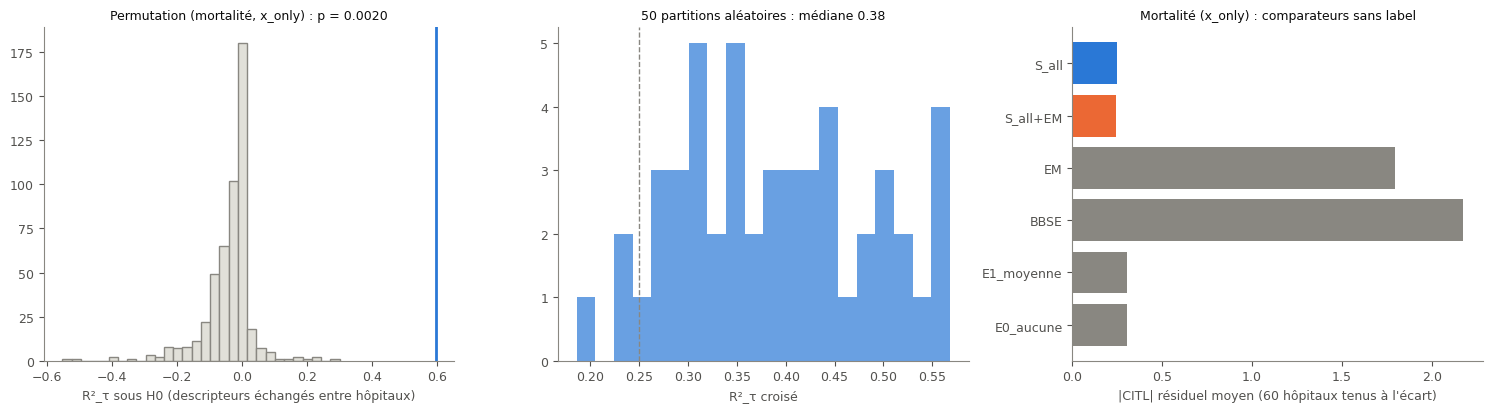

Écrit : ..\results\06c_robustesse_opcal\rapport_06c.md | criteres_06c.csv | specification_gelee.json | comparateurs.csv | permutation.csv | partitions.csv | ablation.csv | transfert_modeles.csv | figures/robustesse_opcal.png


In [11]:
# ============================================================
# ÉTAPE 10 — CONTRÔLES, FIGURES ET RAPPORT
# ============================================================
CONTROLES = []
oc.check("Protocole identique (hash)", protocol["hash"] == EXPECTED_PROTOCOL_HASH, CONTROLES)
oc.check("R²_τ principal du 06b reproduit à l'identique", abs(r2_now - ref06b.loc[(PRIMARY, "S_all"), "R2_tau"]) < 1e-6, CONTROLES)
oc.check("Aucun hôpital verrouillé dans les cibles, descripteurs, sources ou comparateurs",
         all(LOCKED.isdisjoint(CAL[t].index) and LOCKED.isdisjoint(SRC_HOSP[t]["hospitalid"]) and LOCKED.isdisjoint(LS[t].index) for t in CAL)
         and LOCKED.isdisjoint(D_SITE.index), CONTROLES)
oc.check("Source du pli f = hôpitaux d'entraînement du pli f uniquement",
         all((SRC_HOSP[t]["hospitalid"].map(FOLD_OF) != SRC_HOSP[t]["fold"]).all() for t in CAL), CONTROLES)
perm_y = STAYS[PRIMARY].copy()
perm_y["y"] = np.random.default_rng(SEED).permutation(perm_y["y"].to_numpy())
ls_perm = orb.label_shift_predictions(perm_y, REF[PRIMARY])
oc.check("EM et BBSE inchangés quand on permute les labels des hôpitaux tenus à l'écart",
         bool(np.allclose(ls_perm[["a_EM", "a_BBSE"]], LS[PRIMARY][["a_EM", "a_BBSE"]])), CONTROLES)
rng_ = np.random.default_rng(SEED)
def _post(x, pi):
    return 1 / (1 + np.exp(-(2 * x + np.log(pi / (1 - pi)))))
ok_ls = True
for pi_t in (0.05, 0.2, 0.4):
    ys, yt = rng_.random(20000) < 0.1, rng_.random(20000) < pi_t
    xs = np.where(ys, rng_.normal(1, 1, ys.size), rng_.normal(-1, 1, ys.size))
    xt = np.where(yt, rng_.normal(1, 1, yt.size), rng_.normal(-1, 1, yt.size))
    qs, qt = _post(xs, 0.1), _post(xt, 0.1)
    pi_bb = (qt.mean() - qs[~ys].mean()) / (qs[ys].mean() - qs[~ys].mean())
    ok_ls &= abs(orb.em_prior(qt, 0.1) - pi_t) < 0.02 and abs(pi_bb - pi_t) < 0.02
oc.check("EM et BBSE retrouvent la prévalence sous un décalage de labels exact (simulation)", bool(ok_ls), CONTROLES)
oc.check("Spécification gelée : descripteurs exclus et APACHE absents",
         not any(c in EXCLUDED_BY_CONSTRUCTION or c.startswith("apache") for c in SPEC["meta_modele"]["descripteurs"]), CONTROLES)
oc.check("Test verrouillé : seuls hospitalid, role, n_val et n_test du manifest ont été lus", list(man_locked.columns) == man_cols, CONTROLES)
CONTROLES = pd.DataFrame(CONTROLES)
print(f"\n{int(CONTROLES['ok'].sum())}/{len(CONTROLES)} contrôles réussis")

import matplotlib.pyplot as plt
PAL = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": PAL["muted"],
                     "axes.labelcolor": PAL["ink2"], "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "font.size": 9})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
null = PERM[(PRIMARY, "S_all")]
if np.isfinite(null).any():
    axes[0].hist(null[np.isfinite(null)], bins=30, color=PAL["grid"], edgecolor=PAL["muted"])
axes[0].axvline(TAB_PERM.loc[(PRIMARY, "S_all"), "R2_tau_observe"], color=PAL["s1"], lw=2)
axes[0].set_title(f"Permutation (mortalité, x_only) : p = {p1:.4f}", fontsize=9, color=PAL["ink"])
axes[0].set_xlabel("R²_τ sous H0 (descripteurs échangés entre hôpitaux)")
rp = PART[(PRIMARY, "S_all")]
axes[1].hist(rp["R2_tau"], bins=20, color=PAL["s1"], alpha=0.7)
axes[1].axvline(CRIT["R2_R2tau"], color=PAL["muted"], ls="--", lw=1)
axes[1].set_title(f"{N_PART} partitions aléatoires : médiane {m2:.2f}", fontsize=9, color=PAL["ink"])
axes[1].set_xlabel("R²_τ croisé")
tc = TAB_COMP.loc[PRIMARY].reindex(["E0_aucune", "E1_moyenne", "BBSE", "EM", "S_all+EM", "S_all"])
colors = [PAL["muted"]] * 4 + [PAL["s2"], PAL["s1"]]
axes[2].barh(range(len(tc)), tc["mean_abs_citl"], color=colors)
axes[2].set_yticks(range(len(tc))); axes[2].set_yticklabels(tc.index)
axes[2].set_xlabel("|CITL| résiduel moyen (60 hôpitaux tenus à l'écart)")
axes[2].set_title("Mortalité (x_only) : comparateurs sans label", fontsize=9, color=PAL["ink"])
plt.tight_layout(); plt.savefig(FIG_DIR / "robustesse_opcal.png", dpi=200); plt.show()

def md_table(df, digits=3):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    esc = lambda x: str(x).replace("|", "\\|")
    idx = df.index.map(lambda i: " / ".join(map(str, i)) if isinstance(i, tuple) else str(i))
    head = "| " + " | ".join([esc(" / ".join(n for n in df.index.names if n) or "")] + [esc(c) for c in df.columns]) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " | ".join([esc(i)] + [esc(v) for v in row]) + " |" for i, row in zip(idx, df.to_numpy())]
    return "\n".join([head, sep] + body)

rapport = f"""# Rapport 06c — robustesse d'OP-Cal, comparateurs publiés et spécification gelée

Généré le {datetime.now():%Y-%m-%d %H:%M} par `notebooks/06c_robustesse_opcal.ipynb`. Protocole `{protocol['hash']}`. Agrégats uniquement.

## Verdict : {VERDICT} — spécification « {SPEC['statut']} » (SHA-256 `{SPEC_SHA[:16]}…`)

{md_table(CRITERES.set_index('code'))}

## Comparateurs sans label

{md_table(TAB_COMP[COMP_COLS])}

## Permutation

{md_table(TAB_PERM)}

## Partitions aléatoires et leave-one-hospital-out

{md_table(TAB_PART)}

## Ablation

{md_table(TAB_ABL)}

## Transfert du méta-modèle entre modèles

Corrélation des a_h entre modèles :

{md_table(C.corr())}

{md_table(TAB_TRANSF)}

## Spécification gelée

{len(SPEC['meta_modele']['descripteurs'])} descripteurs ; exclus par construction : {', '.join(EXCLUDED_BY_CONSTRUCTION)} ; comparateur publié retenu : {BEST_COMP} ; k confirmatoire = {K_CONF}.

## Contrôles

{md_table(CONTROLES.set_index('controle'))}
"""
(RES_DIR / "rapport_06c.md").write_text(rapport, encoding="utf-8")
print(f"Écrit : {RES_DIR / 'rapport_06c.md'} | criteres_06c.csv | specification_gelee.json | comparateurs.csv | permutation.csv | "
      "partitions.csv | ablation.csv | transfert_modeles.csv | figures/robustesse_opcal.png")